# ImmoAnalyse — Analyse exploratoire (EDA)

**But** : comprendre les données immobilières *après* nettoyage par `pipeline.py`.
On suit toujours le même fil : **aperçu → valeurs manquantes → catégories → distributions → comparaisons → temps → qualité**.



In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Le notebook peut être lancé depuis notebooks/ ou depuis la racine du projet
dossier = Path("../data/propre") if Path("../data/propre").exists() else Path("data/propre")

df = pd.read_csv(dossier / "donnees_propres.csv", parse_dates=["date"])
quarantaine = pd.read_csv(dossier / "quarantaine.csv")

pd.options.display.float_format = "{:,.0f}".format   # nombres lisibles : 59,523,000
print(f"Données propres : {len(df)} lignes | Quarantaine : {len(quarantaine)} lignes")

Données propres : 3001 lignes | Quarantaine : 183 lignes


## 1. Aperçu général

In [2]:
df.head()

,id_local,source,date,type_transaction,type_bien,region,ville,prix,surface,chambres,salles_bain,statut,prix_m2,avertissements,corrige,doublon_exact,doublon_probable
0,PLT-00001,plateforme,2020-07-03,vente,Appartement,Tambacounda,Tambacounda,"60,581,000",173,1,1,Vendu,"349,573",NaN,False,False,False
1,PLT-00002,plateforme,2022-09-15,vente,Maison,Kolda,Kolda,"57,620,000",90,5,3,Vendu,"643,080",NaN,True,False,False
2,PLT-00003,plateforme,2019-01-15,vente,Terrain,Diourbel,Touba,"9,688,000","1,457",0,0,Vendu,"6,648",NaN,False,False,False
3,PLT-00004,plateforme,2025-01-18,vente,Appartement,Thiès,Joal-Fadiouth,"42,273,000",70,3,2,En vente,"605,630",NaN,False,False,False
4,PLT-00005,plateforme,2022-02-03,vente,Studio,Kaffrine,Kaffrine,"26,254,000",32,3,2,Vendu,"830,823",NaN,False,False,False


In [3]:
df.info()      # colonnes, types, nombre de valeurs non vides

<class 'pandas.DataFrame'>
RangeIndex: 3001 entries, 0 to 3000
Data columns (total 17 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   id_local          3001 non-null   str           
 1   source            3001 non-null   str           
 2   date              3001 non-null   datetime64[us]
 3   type_transaction  3001 non-null   str           
 4   type_bien         3001 non-null   str           
 5   region            3001 non-null   str           
 6   ville             2993 non-null   str           
 7   prix              3001 non-null   float64       
 8   surface           3001 non-null   float64       
 9   chambres          3001 non-null   int64         
 10  salles_bain       2611 non-null   float64       
 11  statut            3001 non-null   str           
 12  prix_m2           3001 non-null   float64       
 13  avertissements    174 non-null    str           
 14  corrige           3001 non-null   b

In [4]:
df.describe()  # min, max, moyenne, quartiles des colonnes numériques

,date,prix,surface,chambres,salles_bain,prix_m2
count,3001,"3,001","3,001","3,001","2,611","3,001"
mean,2021-08-01 22:04:50.303232,"88,717,980",240,3,2,"631,145"
min,2018-01-01 00:00:00,"40,000",10,0,0,37
25%,2019-06-06 00:00:00,"22,681,000",72,1,1,"146,096"
50%,2021-04-23 00:00:00,"59,523,000",147,3,2,"532,019"
75%,2023-10-14 00:00:00,"116,116,000",246,5,3,"895,002"
max,2028-12-01 00:00:00,"567,559,000","1,495",6,4,"18,747,500"
std,NaN,"97,769,330",292,2,1,"667,387"


## 2. Valeurs manquantes
On regarde le **pourcentage de cases vides** par colonne. (Les colonnes `avertissements` vides sont normales : "" = aucun avertissement.)

In [5]:
manquantes = (df.isna().mean() * 100).round(1).sort_values(ascending=False)
manquantes[manquantes > 0].to_frame("% vide").style.format("{:.1f} %")

,% vide
avertissements,94.2 %
salles_bain,13.0 %
ville,0.3 %


## 3. Répartition des catégories
Combien d'annonces par source, par type de transaction, par type de bien ?

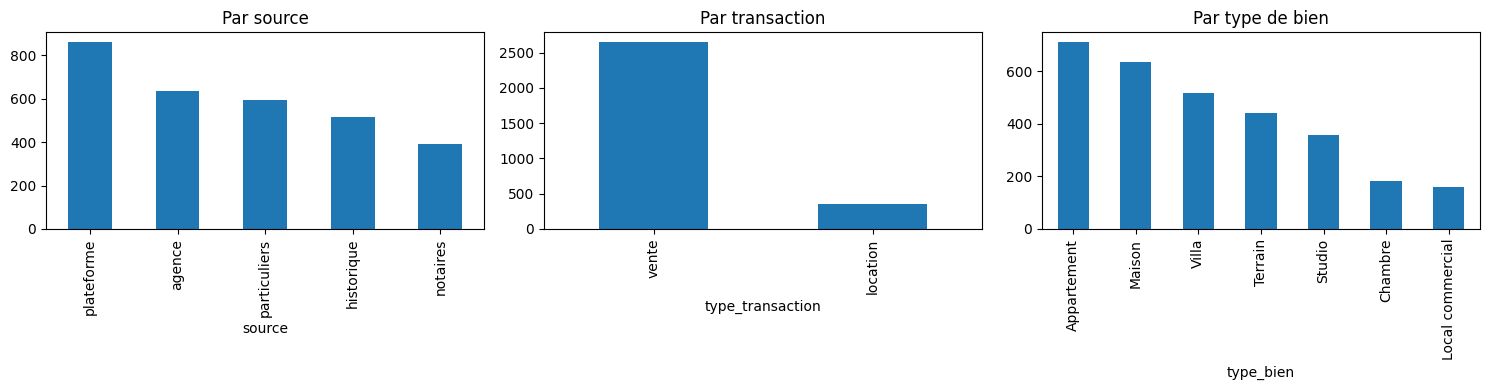

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

df["source"].value_counts().plot.bar(ax=axes[0], title="Par source")
df["type_transaction"].value_counts().plot.bar(ax=axes[1], title="Par transaction")
df["type_bien"].value_counts().plot.bar(ax=axes[2], title="Par type de bien")

plt.tight_layout()
plt.show()

In [7]:
df["statut"].value_counts()

statut
Vendu            1652
En vente          643
Disponible        247
Loué              192
Vente conclue      82
Sous offre         61
À confirmer        46
Acte signé         41
Retiré             37
Name: count, dtype: int64

## 4. Distributions numériques
On analyse **uniquement les ventes** : un loyer mensuel et un prix de vente ne se comparent pas.

In [8]:
ventes = df[df["type_transaction"] == "vente"]
print(f"{len(ventes)} ventes sur {len(df)} annonces")

2654 ventes sur 3001 annonces


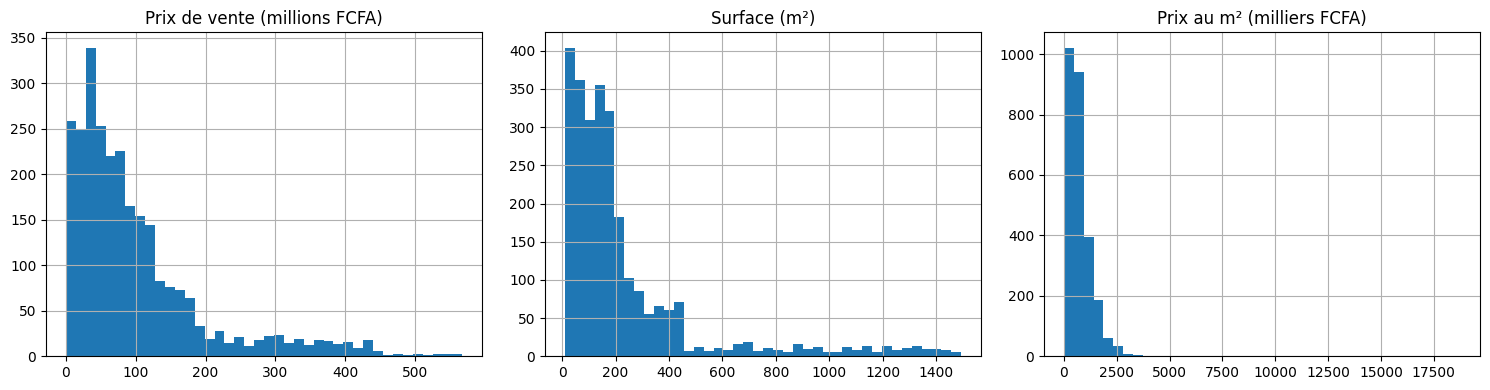

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

(ventes["prix"] / 1e6).hist(bins=40, ax=axes[0])
axes[0].set_title("Prix de vente (millions FCFA)")

ventes["surface"].hist(bins=40, ax=axes[1])
axes[1].set_title("Surface (m²)")

(ventes["prix_m2"] / 1e3).hist(bins=40, ax=axes[2])
axes[2].set_title("Prix au m² (milliers FCFA)")

plt.tight_layout()
plt.show()

In [10]:
print(f"Prix médian     : {ventes['prix'].median():,.0f} FCFA")
print(f"Prix moyen      : {ventes['prix'].mean():,.0f} FCFA")
print(f"Surface médiane : {ventes['surface'].median():.0f} m²")
print(f"Prix/m² médian  : {ventes['prix_m2'].median():,.0f} FCFA")

Prix médian     : 71,236,500 FCFA
Prix moyen      : 100,264,320 FCFA
Surface médiane : 146 m²
Prix/m² médian  : 601,711 FCFA


## 5. Valeurs extrêmes (outliers)
Une **boîte à moustaches** montre la médiane (trait), les quartiles (boîte) et les valeurs extrêmes (points).

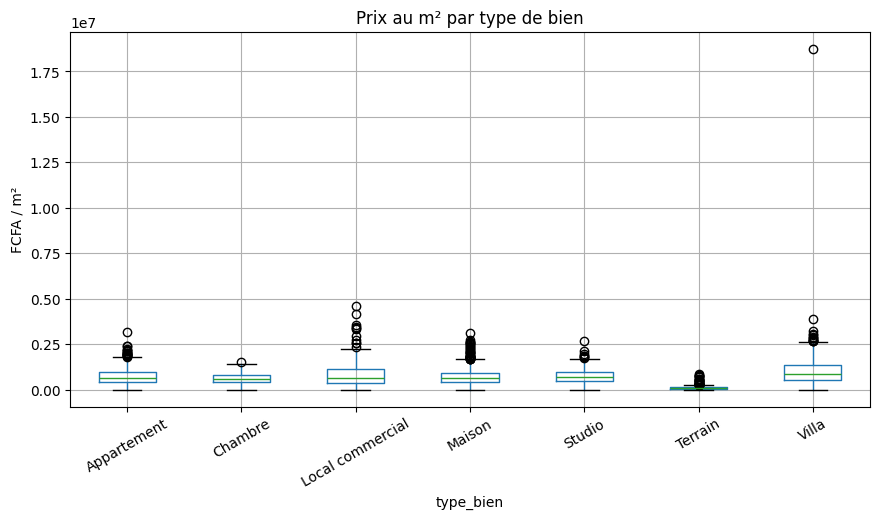

In [11]:
ventes.boxplot(column="prix_m2", by="type_bien", figsize=(10, 5), rot=30)
plt.title("Prix au m² par type de bien")
plt.suptitle("")
plt.ylabel("FCFA / m²")
plt.show()

## 6. Comparaisons : par type de bien, par ville, par source


In [12]:
par_type = ventes.groupby("type_bien").agg(
    nombre=("prix", "count"),
    prix_median=("prix", "median"),
    surface_mediane=("surface", "median"),
    prix_m2_median=("prix_m2", "median"),
).sort_values("prix_median", ascending=False)
par_type

,nombre,prix_median,surface_mediane,prix_m2_median
type_bien,,,,
Villa,473,"253,057,000",296,"873,124"
Local commercial,145,"101,457,000",178,"622,357"
Maison,563,"100,052,000",157,"651,279"
Appartement,617,"67,783,000",110,"643,428"
Terrain,375,"47,841,000",760,"63,085"
Studio,318,"28,316,000",39,"719,335"
Chambre,163,"11,675,000",20,"562,577"


In [13]:
par_ville = ventes.groupby("ville").agg(
    nombre=("prix", "count"),
    prix_median=("prix", "median"),
    prix_m2_median=("prix_m2", "median"),
)
# Villes avec au moins 20 ventes (sinon la médiane n'est pas fiable)
par_ville[par_ville["nombre"] >= 20].sort_values("prix_m2_median", ascending=False).head(10)

,nombre,prix_median,prix_m2_median
ville,,,
Dakar,46,"83,587,500","938,530"
Rufisque,54,"118,121,500","807,320"
Pikine,44,"102,533,500","762,646"
Saint-Louis,57,"92,359,000","723,157"
Touba,45,"77,142,000","706,127"
Birkelane,46,"68,469,500","697,894"
Ourossogui,72,"66,640,500","691,062"
Joal-Fadiouth,43,"68,350,000","664,612"
Vélingara,64,"83,238,500","659,976"


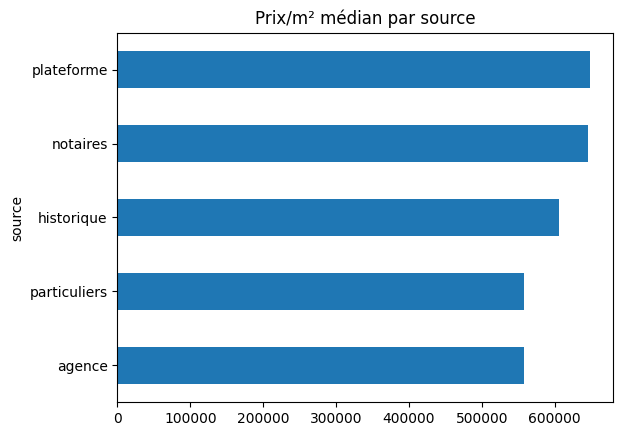

In [14]:
ventes.groupby("source")["prix_m2"].median().sort_values().plot.barh(title="Prix/m² médian par source")
plt.show()

## 7. Évolution dans le temps

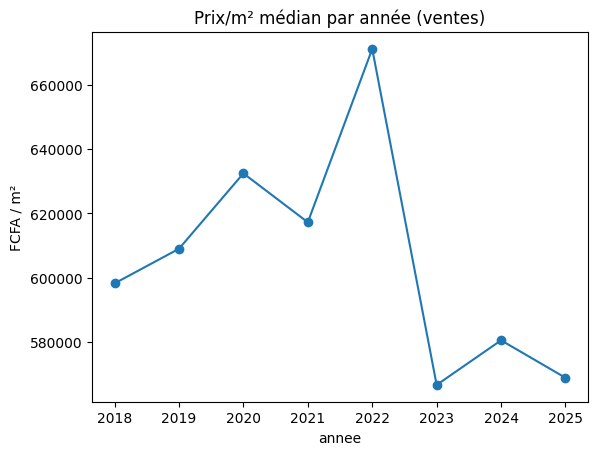

In [15]:
# On exclut les dates futures (annonces datées 2028), qui n'ont pas de sens pour une évolution passée
passe = ventes[ventes["date"] <= pd.Timestamp.today()]
ventes_par_annee = passe.assign(annee=passe["date"].dt.year)
evolution = ventes_par_annee.groupby("annee")["prix_m2"].median()
evolution.plot(marker="o", title="Prix/m² médian par année (ventes)")
plt.ylabel("FCFA / m²")
plt.show()

In [16]:
ventes_par_annee["annee"].value_counts().sort_index()   # attention : peu d'annonces = courbe peu fiable

annee
2018    497
2019    524
2020    274
2021    261
2022    278
2023    262
2024    294
2025    260
Name: count, dtype: int64

## 8. Corrélations
Une corrélation proche de **1** = les deux colonnes montent ensemble ; proche de **0** = pas de lien linéaire.

In [17]:
ventes[["prix", "surface", "chambres", "salles_bain"]].corr().style.format("{:.2f}").background_gradient(cmap="coolwarm", vmin=-1, vmax=1)

,prix,surface,chambres,salles_bain
prix,1.00,0.04,0.10,0.21
surface,0.04,1.00,-0.43,-0.39
chambres,0.10,-0.43,1.00,0.34
salles_bain,0.21,-0.39,0.34,1.00


## 9. Qualité : la quarantaine
Pourquoi des lignes ont-elles été rejetées ? (une ligne peut avoir plusieurs motifs)

In [18]:
motifs = quarantaine["motifs_rejet"].str.split(" | ", regex=False).explode()
motifs.value_counts()

motifs_rejet
prix absent ou invalide           98
surface absente ou invalide       84
date absente ou invalide           6
date future pour un bien vendu     1
Name: count, dtype: int64

In [19]:
# Exemples de valeurs brutes rejetées
quarantaine[["source", "id_local", "prix", "surface", "date", "motifs_rejet"]].head(8)

,source,id_local,prix,surface,date,motifs_rejet
0,plateforme,PLT-00062,à négocier,1131.9,2023-04-04,prix absent ou invalide
1,plateforme,PLT-00077,64862000,78.4,2028-12-01,date future pour un bien vendu
2,plateforme,PLT-00085,à négocier,163.7,2025-11-11,prix absent ou invalide
3,plateforme,PLT-00211,595000,NaN,2020-08-07,surface absente ou invalide
4,plateforme,PLT-00222,à négocier,55.1,2019-06-25,prix absent ou invalide
5,plateforme,PLT-00249,162813000,NaN,2022-04-18,surface absente ou invalide
6,plateforme,PLT-00507,85240000,NaN,2023-09-10,surface absente ou invalide
7,plateforme,PLT-00676,à négocier,472.4,2021-07-24,prix absent ou invalide


## 10. Qualité : avertissements, corrections et doublons

In [20]:
total = len(df) + len(quarantaine)
print(f"Reçues        : {total}")
print(f"Conservées    : {len(df)}  ({100 * len(df) / total:.1f} %)")
print(f"Quarantaine   : {len(quarantaine)}  ({100 * len(quarantaine) / total:.1f} %)")
print(f"Corrigées     : {df['corrige'].sum()}")
print(f"Doublons exacts / probables : {df['doublon_exact'].sum()} / {df['doublon_probable'].sum()}")

Reçues        : 3184
Conservées    : 3001  (94.3 %)
Quarantaine   : 183  (5.7 %)
Corrigées     : 419
Doublons exacts / probables : 28 / 81


In [21]:
avertissements = df["avertissements"].fillna("").str.split(" | ", regex=False).explode()
avertissements[avertissements != ""].value_counts()

avertissements
salles de bain > chambres + 2    155
prix de vente atypique            11
date future                        4
ville/région incohérentes          4
Name: count, dtype: int64

In [22]:
# Exemples de doublons exacts : même ville, type, surface, date et prix (et ici même identifiant)
df[df["doublon_exact"]].sort_values(["ville", "prix"])[["source", "id_local", "ville", "type_bien", "surface", "prix"]].head(8)

,source,id_local,ville,type_bien,surface,prix
487,plateforme,PLT-00494,Fatick,Appartement,78,"34,171,000"
859,plateforme,PLT-00494,Fatick,Appartement,78,"34,171,000"
682,plateforme,PLT-00692,Goudiry,Maison,106,"127,465,000"
849,plateforme,PLT-00692,Goudiry,Maison,106,"127,465,000"
617,plateforme,PLT-00625,Goudomp,Appartement,132,"260,000"
862,plateforme,PLT-00625,Goudomp,Appartement,132,"260,000"
648,plateforme,PLT-00656,Kanel,Maison,192,"695,000"
854,plateforme,PLT-00656,Kanel,Maison,192,"695,000"


## 11. Conclusions

1. **Qualité** : sur 3 184 annonces reçues, 3 001 sont conservées (94,3 %) et 183 partent en quarantaine, surtout pour un prix absent ou « à négocier » (98) ou une surface invalide (84).
2. **Doublons** : les 14 groupes de doublons exacts sont des lignes répétées *dans la même source* (la plateforme) avec le même identifiant, ce qui ressemble à un double import. Les 81 doublons probables restent à vérifier à la main (on ne les supprime pas automatiquement).
3. **Prix des ventes** : médiane ≈ 71 M FCFA contre une moyenne ≈ 100 M. Cet écart montre une distribution étalée vers la droite : quelques biens très chers tirent la moyenne vers le haut, d'où l'usage de la médiane.
4. **Types de biens** : la villa est le bien le plus cher (médiane ≈ 253 M FCFA), la chambre le moins cher (≈ 12 M). Le terrain a un prix au m² très bas (≈ 63 000 FCFA contre 560 000 à 870 000 pour les autres) parce que ses surfaces sont très grandes.
5. **Villes** (au moins 20 ventes) : Dakar a le prix au m² médian le plus élevé (≈ 939 000 FCFA), devant Rufisque et Pikine.
6. **Temps** : le prix au m² médian varie entre ≈ 567 000 et ≈ 671 000 FCFA selon l'année, sans tendance nette. Il y a environ deux fois plus d'annonces en 2018-2019 qu'ensuite.
7. **Corrélations** : le prix est très peu lié à la surface (0,04) car on mélange des types de biens très différents ; la surface baisse quand le nombre de chambres monte (−0,43), ce qui est contre-intuitif.
8. **Limites** : 155 annonces ont plus de salles de bain que chambres + 2, et 4 annonces sont datées du 1er décembre 2028 (date probablement par défaut) : elles sont conservées avec un avertissement. Les données sont synthétiques : ne pas extrapoler au marché réel.